# Logistic Regression Exercises

Now that we've learned about **Logistic Regression**, let's test your knowledge. This assignment follows the same workflow as the lecture: inspect the dataset, prepare the input and target variables, split the data, train a classifier, make predictions, evaluate accuracy, and visualize the results.

The questions begin with simple tasks and gradually move to more challenging applications.

**Instructions**
- Write your answers only in cells marked `# CODE HERE`.
- Run the provided setup cells before answering the questions.
- Do not edit cells marked `# DON'T WRITE HERE`; they contain reference outputs.
- Run the notebook from top to bottom.
- The dataset in this notebook is synthetic and is provided only for programming practice. It is not real patient data and must not be used for medical decisions.


## Part 1: Import Libraries and Explore the Dataset

#### 1. Import NumPy as `np`, pandas as `pd`, `train_test_split`, `LogisticRegression`, `confusion_matrix`, `accuracy_score`, seaborn as `sns`, and `matplotlib.pyplot` as `plt`.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# RUN THIS CELL - STARTING DATASET
# This is a synthetic teaching dataset with the same target-column idea used in the lecture.
# The values are generated deterministically so every student receives the same data.

rng = np.random.default_rng(42)
n_samples = 180

age = rng.integers(40, 91, n_samples)
anaemia = rng.integers(0, 2, n_samples)
diabetes = rng.integers(0, 2, n_samples)
ejection_fraction = rng.integers(15, 71, n_samples)
high_blood_pressure = rng.integers(0, 2, n_samples)
serum_creatinine = np.round(rng.uniform(0.5, 3.5, n_samples), 2)
smoking = rng.integers(0, 2, n_samples)

risk_score = (
    0.045 * (age - 60)
    - 0.075 * (ejection_fraction - 35)
    + 0.55 * (serum_creatinine - 1.2)
    + 0.35 * anaemia
    + 0.30 * high_blood_pressure
    + 0.25 * diabetes
    + 0.15 * smoking
    + rng.normal(0, 0.9, n_samples)
)

DEATH_EVENT = (risk_score > np.quantile(risk_score, 0.65)).astype(int)

data = pd.DataFrame({
    'age': age,
    'anaemia': anaemia,
    'diabetes': diabetes,
    'ejection_fraction': ejection_fraction,
    'high_blood_pressure': high_blood_pressure,
    'serum_creatinine': serum_creatinine,
    'smoking': smoking,
    'DEATH_EVENT': DEATH_EVENT
})

data.head()

,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,serum_creatinine,smoking,DEATH_EVENT
0,44,1,1,54,0,0.63,0,0
1,79,0,1,18,1,3.15,1,1
2,73,0,0,25,1,2.63,0,1
3,62,1,1,24,0,1.02,1,0
4,62,0,0,61,1,0.78,0,0


#### 2. Display the first five rows of the `data` DataFrame.

In [3]:
data.head()

,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,serum_creatinine,smoking,DEATH_EVENT
0,44,1,1,54,0,0.63,0,0
1,79,0,1,18,1,3.15,1,1
2,73,0,0,25,1,2.63,0,1
3,62,1,1,24,0,1.02,1,0
4,62,0,0,61,1,0.78,0,0


In [2]:
# DON'T WRITE HERE

   age  anaemia  diabetes  ejection_fraction  high_blood_pressure  serum_creatinine  smoking  DEATH_EVENT
0   44        1         1                 54                    0              0.63        0            0
1   79        0         1                 18                    1              3.15        1            1
2   73        0         0                 25                    1              2.63        0            1
3   62        1         1                 24                    0              1.02        1            0
4   62        0         0                 61                    1              0.78        0            0

#### 3. Find the number of rows and columns in `data` using `.shape`.

In [4]:
data.shape

(180, 8)

In [3]:
# DON'T WRITE HERE

(180, 8)

#### 4. Display all column names in `data` using `.columns`.

In [5]:
data.columns

Index(['age', 'anaemia', 'diabetes', 'ejection_fraction',
       'high_blood_pressure', 'serum_creatinine', 'smoking', 'DEATH_EVENT'],
      dtype='object')

In [4]:
# DON'T WRITE HERE

Index(['age', 'anaemia', 'diabetes', 'ejection_fraction',
       'high_blood_pressure', 'serum_creatinine', 'smoking', 'DEATH_EVENT'],
      dtype='object')

#### 5. Use `data.info()` to inspect the data types and non-null values.

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  180 non-null    int64  
 1   anaemia              180 non-null    int64  
 2   diabetes             180 non-null    int64  
 3   ejection_fraction    180 non-null    int64  
 4   high_blood_pressure  180 non-null    int64  
 5   serum_creatinine     180 non-null    float64
 6   smoking              180 non-null    int64  
 7   DEATH_EVENT          180 non-null    int64  
dtypes: float64(1), int64(7)
memory usage: 11.4 KB


#### 6. Check the number of missing values in every column using `isnull().sum()`.

In [7]:
data.isnull().sum()

age                    0
anaemia                0
diabetes               0
ejection_fraction      0
high_blood_pressure    0
serum_creatinine       0
smoking                0
DEATH_EVENT            0
dtype: int64

In [6]:
# DON'T WRITE HERE

age                    0
anaemia                0
diabetes               0
ejection_fraction      0
high_blood_pressure    0
serum_creatinine       0
smoking                0
DEATH_EVENT            0

#### 7. Count how many records belong to each class in the `DEATH_EVENT` column using `value_counts()`.

In [8]:
data['DEATH_EVENT'].value_counts()

DEATH_EVENT
0    117
1     63
Name: count, dtype: int64

In [7]:
# DON'T WRITE HERE

DEATH_EVENT
0    117
1     63

## Part 2: Prepare the Input and Target Variables

#### 8. Create the input variable `x` using all columns except the last column of `data` and `iloc`.

In [10]:
x = data.iloc[:, :-1]

#### 9. Create the target variable `y` using the last column of `data` and `iloc`.

In [11]:
y = data.iloc[:, -1]

#### 10. Display the first five rows of `x`.

In [12]:
x.head()

,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,serum_creatinine,smoking
0,44,1,1,54,0,0.63,0
1,79,0,1,18,1,3.15,1
2,73,0,0,25,1,2.63,0
3,62,1,1,24,0,1.02,1
4,62,0,0,61,1,0.78,0


In [10]:
# DON'T WRITE HERE

   age  anaemia  diabetes  ejection_fraction  high_blood_pressure  serum_creatinine  smoking
0   44        1         1                 54                    0              0.63        0
1   79        0         1                 18                    1              3.15        1
2   73        0         0                 25                    1              2.63        0
3   62        1         1                 24                    0              1.02        1
4   62        0         0                 61                    1              0.78        0

#### 11. Display the first five values of `y`.

In [13]:
y.head()

0    0
1    1
2    1
3    0
4    0
Name: DEATH_EVENT, dtype: int64

In [11]:
# DON'T WRITE HERE

0    0
1    1
2    1
3    0
4    0

## Part 3: Split the Data and Train the Model

#### 12. Split `x` and `y` into training and testing sets using `train_test_split()`. Use `train_size=0.8` and `random_state=42`. Store the results in `x_train`, `x_test`, `y_train`, and `y_test`.

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=42)

#### 13. Print the shapes of `x_train`, `x_test`, `y_train`, and `y_test`.

In [15]:
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (144, 7)
x_test: (36, 7)
y_train: (144,)
y_test: (36,)


In [13]:
# DON'T WRITE HERE

x_train: (144, 7)
x_test: (36, 7)
y_train: (144,)
y_test: (36,)

#### 14. Create a Logistic Regression model and store it in a variable named `model`.

In [16]:
model = LogisticRegression()

#### 15. Train `model` using `x_train` and `y_train` with the `fit()` method.

In [17]:
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


#### 16. Use `model.predict()` to predict the classes of `x_test`. Store the predictions in `y_pred`.

In [18]:
y_pred = model.predict(x_test)

#### 17. Display the first ten values of `y_pred`.

In [19]:
y_pred[:10]

array([0, 1, 0, 1, 0, 1, 0, 0, 0, 1])

In [17]:
# DON'T WRITE HERE

array([0, 1, 0, 1, 0, 1, 0, 0, 0, 1])

#### 18. Display the first ten actual values from `y_test`.

In [20]:
y_test.head(10)

19     0
42     1
153    0
78     1
145    0
15     0
24     0
68     0
113    0
118    1
Name: DEATH_EVENT, dtype: int64

In [18]:
# DON'T WRITE HERE

19     0
42     1
153    0
78     1
145    0
15     0
24     0
68     0
113    0
118    1

#### 19. Create a DataFrame named `comparison` with two columns: `Actual` (from `y_test`) and `Predicted` (from `y_pred`). Display its first five rows.

In [21]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

comparison.head()

,Actual,Predicted
19,0,0
42,1,1
153,0,0
78,1,1
145,0,0


In [19]:
# DON'T WRITE HERE

     Actual  Predicted
19        0          0
42        1          1
153       0          0
78        1          1
145       0          0

## Part 4: Evaluate the Model

#### 20. Calculate the training accuracy using `model.score(x_train, y_train)` and print the result.

In [22]:
train_acc = model.score(x_train, y_train)
print("Training Accuracy:", train_acc)

Training Accuracy: 0.8680555555555556


In [20]:
# DON'T WRITE HERE

Training Accuracy: 0.8680555555555556

#### 21. Calculate the testing accuracy using `model.score(x_test, y_test)` and print the result.

In [23]:
test_acc = model.score(x_test, y_test)
print("Testing Accuracy:", test_acc)

Testing Accuracy: 0.8888888888888888


In [21]:
# DON'T WRITE HERE

Testing Accuracy: 0.8888888888888888

#### 22. Calculate the accuracy again using `accuracy_score(y_test, y_pred)` and print the result.

In [24]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy Score:", acc)

Accuracy Score: 0.8888888888888888


In [22]:
# DON'T WRITE HERE

Accuracy Score: 0.8888888888888888

## Part 5: Visualize Actual and Predicted Classes

#### 23. Create a variable named `colors` using `np.where()`. Use `'red'` when the actual value in `y_test` is `1`, and `'blue'` when it is `0`.

In [25]:
colors = np.where(y_test == 1, 'red', 'blue')

In [23]:
# DON'T WRITE HERE

array(['blue', 'red', 'blue', 'red', 'blue', 'blue', 'blue', 'blue',
       'blue', 'red'], dtype='<U4')

#### 24. Use `plt.scatter()` to draw the **actual test data**. Put the first column of `x_test` on the x-axis and `y_test` on the y-axis. Use `colors`, circular markers, axis labels, a title, a legend, and `plt.show()`.

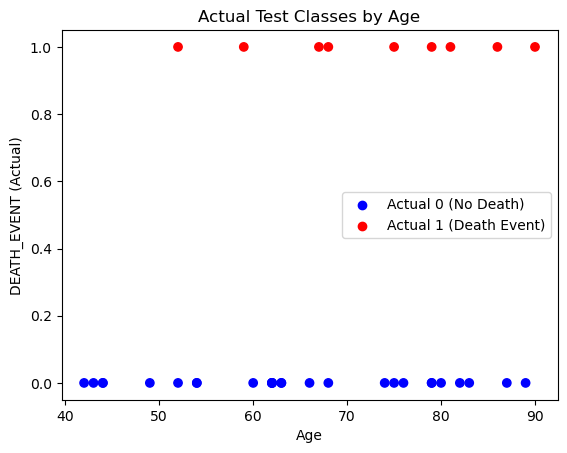

In [26]:
plt.scatter(x_test.iloc[:, 0], y_test, c=colors, marker='o')

# إضافة عناصر وهمية لإنشاء وسيلة إيضاح (Legend) توضح دلالة كل لون
plt.scatter([], [], c='blue', marker='o', label='Actual 0 (No Death)')
plt.scatter([], [], c='red', marker='o', label='Actual 1 (Death Event)')

plt.xlabel('Age')
plt.ylabel('DEATH_EVENT (Actual)')
plt.title('Actual Test Classes by Age')
plt.legend()
plt.show()

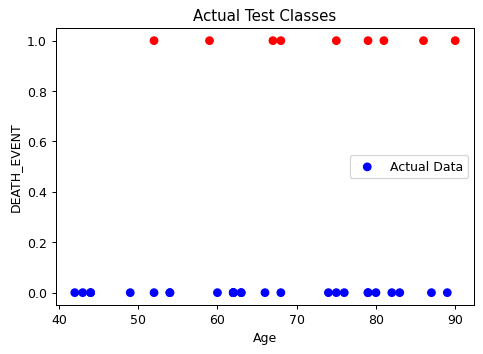

In [24]:
# DON'T WRITE HERE

#### 25. Use `plt.scatter()` to draw the **predicted test data**. Put the first column of `x_test` on the x-axis and `y_pred` on the y-axis. Use green `x` markers, axis labels, a title, a legend, and `plt.show()`.

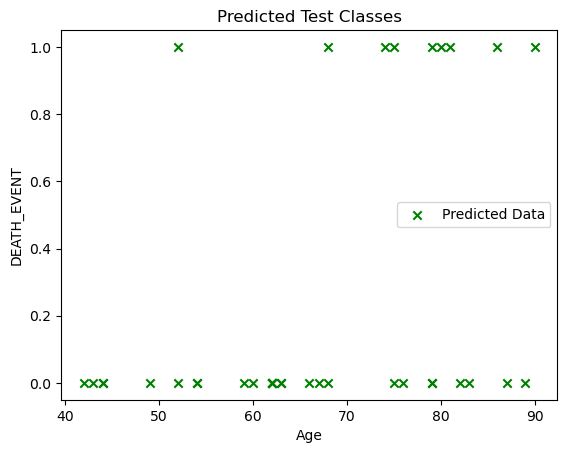

In [27]:
plt.scatter(x_test.iloc[:, 0], y_pred, color='green', marker='x', label='Predicted Data')
plt.xlabel('Age')
plt.ylabel('DEATH_EVENT')
plt.title('Predicted Test Classes')
plt.legend()
plt.show()

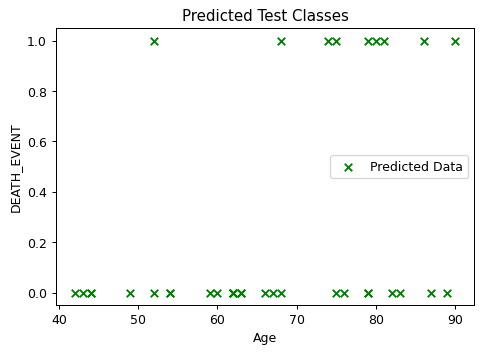

In [25]:
# DON'T WRITE HERE

#### 26. Draw a pie chart showing the distribution of actual classes in `y_test`. Use `np.sum()` to count class `0` and class `1`, label the slices, and display percentages.

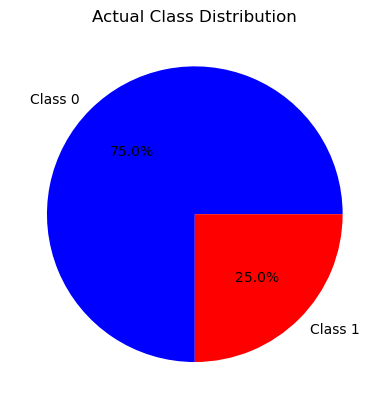

In [28]:
count_0 = np.sum(y_test == 0)
count_1 = np.sum(y_test == 1)

counts = [count_0, count_1]
labels = ['Class 0', 'Class 1']
colors = ['blue', 'red']

plt.pie(counts, labels=labels, colors=colors, autopct='%1.1f%%')
plt.title('Actual Class Distribution')
plt.show()

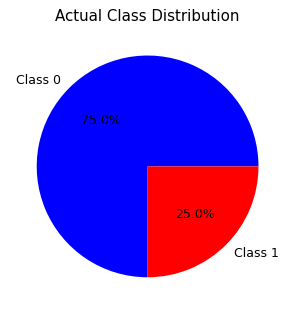

In [26]:
# DON'T WRITE HERE

#### 27. Draw a pie chart showing the distribution of predicted classes in `y_pred`. Use `np.sum()` to count class `0` and class `1`, label the slices, and display percentages.

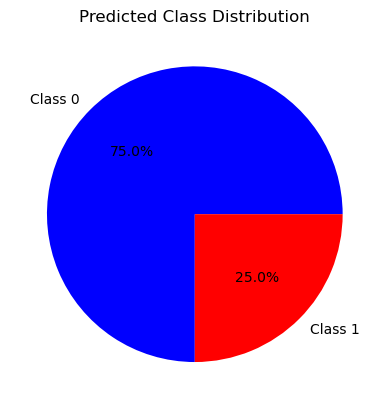

In [29]:
pred_count_0 = np.sum(y_pred == 0)
pred_count_1 = np.sum(y_pred == 1)

pred_counts = [pred_count_0, pred_count_1]
labels = ['Class 0', 'Class 1']
colors = ['blue', 'red']

plt.pie(pred_counts, labels=labels, colors=colors, autopct='%1.1f%%')
plt.title('Predicted Class Distribution')
plt.show()

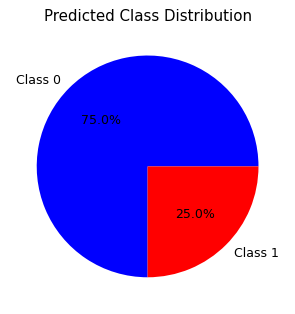

In [27]:
# DON'T WRITE HERE

#### 28. Draw a bar chart for the actual class counts in `y_test`. Use the labels `Class 0` and `Class 1`, and use blue and red bars respectively.

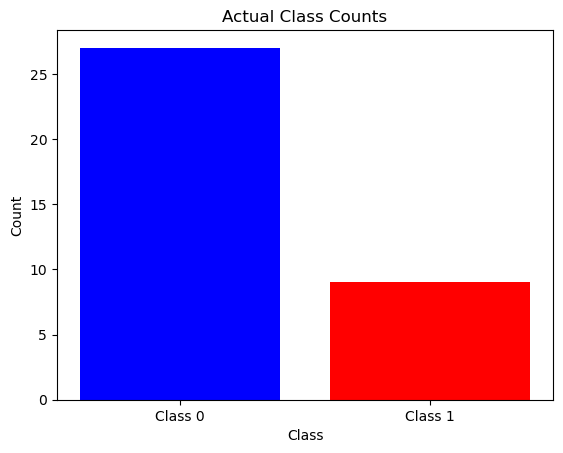

In [32]:
actual_counts = [np.sum(y_test == 0), np.sum(y_test == 1)]
labels = ['Class 0', 'Class 1']
colors = ['blue', 'red']

plt.bar(labels, actual_counts, color=colors)
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Actual Class Counts')
plt.show()

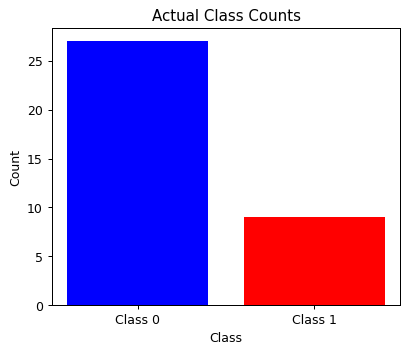

In [28]:
# DON'T WRITE HERE

#### 29. Draw a bar chart for the predicted class counts in `y_pred`. Use the labels `Class 0` and `Class 1`, and use blue and red bars respectively.

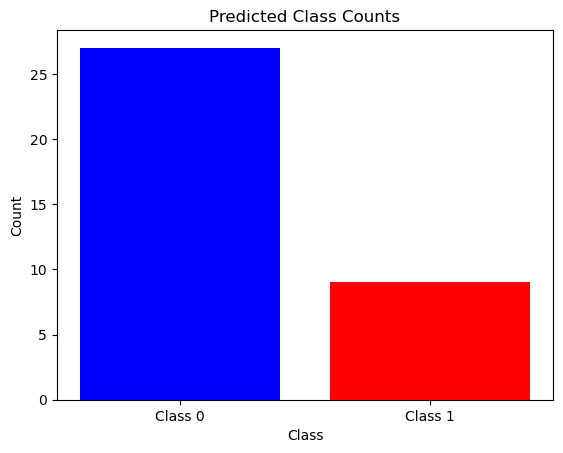

In [31]:
pred_counts = [np.sum(y_pred == 0), np.sum(y_pred == 1)]
labels = ['Class 0', 'Class 1']
colors = ['blue', 'red']

plt.bar(labels, pred_counts, color=colors)
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Predicted Class Counts')
plt.show()

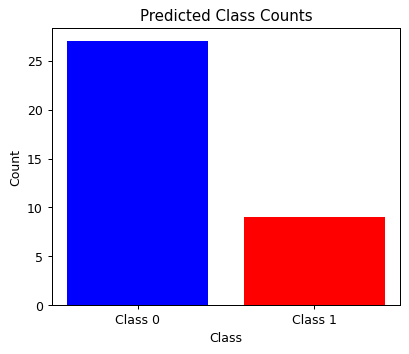

In [29]:
# DON'T WRITE HERE

## Part 6: Confusion Matrix and Error Analysis

#### 30. Create a confusion matrix using `confusion_matrix(y_test, y_pred)`. Store it in `conf_matrix` and display it.

In [33]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix

array([[25,  2],
       [ 2,  7]])

In [30]:
# DON'T WRITE HERE

array([[25,  2],
       [ 2,  7]])

#### 31. Use `sns.heatmap()` to draw `conf_matrix`. Set `annot=True`, `fmt='d'`, and use `xticklabels` and `yticklabels` as `['Class 0', 'Class 1']`. Add axis labels, a title, and display the plot.

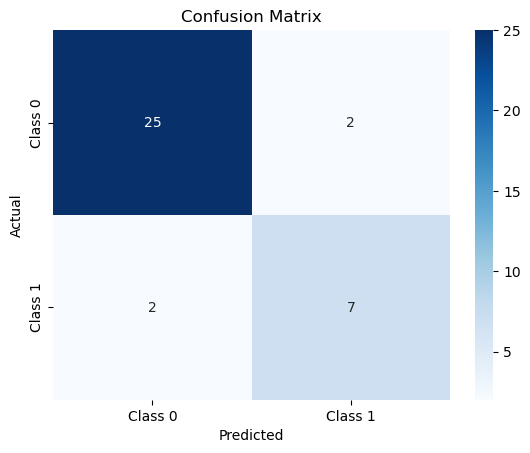

In [34]:
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

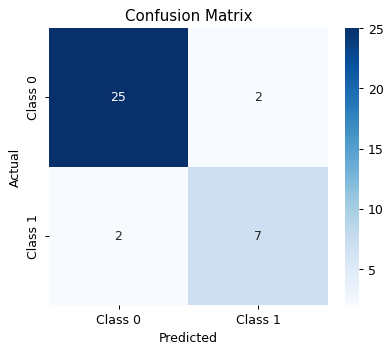

In [31]:
# DON'T WRITE HERE

#### 32. Using the `comparison` DataFrame, create `wrong_predictions` containing only the rows where `Actual` and `Predicted` are different. Display the result and print its number of rows.

In [35]:
wrong_predictions = comparison[comparison['Actual'] != comparison['Predicted']]
print(wrong_predictions)
print("Number of wrong predictions:", len(wrong_predictions))

    Actual  Predicted
15       0          1
93       1          0
56       1          0
97       0          1
Number of wrong predictions: 4


In [32]:
# DON'T WRITE HERE

    Actual  Predicted
15       0          1
93       1          0
56       1          0
97       0          1
Number of wrong predictions: 4

## Part 7: Applied Classification Challenge

The following questions require you to reuse the same Logistic Regression workflow from the lecture. Use only the columns and methods already introduced.


#### 33. Unpack `conf_matrix` into four variables named `tn`, `fp`, `fn`, and `tp` using `.ravel()`. Print the four values with clear labels.

In [36]:
tn, fp, fn, tp = conf_matrix.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 25
FP: 2
FN: 2
TP: 7


In [33]:
# DON'T WRITE HERE

TN: 25
FP: 2
FN: 2
TP: 7

#### 34. Create a list named `selected_features` containing `['age', 'ejection_fraction', 'serum_creatinine']`. Create a second Logistic Regression model named `model_small`, train it using only these columns from `x_train`, then calculate and print its accuracy on the matching columns from `x_test`.

In [37]:
selected_features = ['age', 'ejection_fraction', 'serum_creatinine']

model_small = LogisticRegression()
model_small.fit(x_train[selected_features], y_train)

small_acc = model_small.score(x_test[selected_features], y_test)
print("Small Model Accuracy:", small_acc)

Small Model Accuracy: 0.8611111111111112


In [34]:
# DON'T WRITE HERE

Accuracy using three features: 0.8611111111111112

#### New Records for Prediction

Run the following cell to create three new synthetic records. The values and column order match the input columns used to train `model`.


In [38]:
# RUN THIS CELL - NEW SYNTHETIC RECORDS
new_cases = pd.DataFrame({
    'age': [50, 80, 67],
    'anaemia': [0, 1, 0],
    'diabetes': [0, 1, 1],
    'ejection_fraction': [55, 20, 30],
    'high_blood_pressure': [0, 1, 1],
    'serum_creatinine': [0.9, 2.8, 1.8],
    'smoking': [0, 1, 0]
})
new_cases

,age,anaemia,diabetes,ejection_fraction,high_blood_pressure,serum_creatinine,smoking
0,50,0,0,55,0,0.9,0
1,80,1,1,20,1,2.8,1
2,67,0,1,30,1,1.8,0


#### 35. Use `model.predict()` to predict the classes of `new_cases`. Store the result in `new_predictions` and display it.

In [39]:
new_predictions = model.predict(new_cases)
new_predictions

array([0, 1, 1])

In [35]:
# DON'T WRITE HERE

array([0, 1, 1])

#### 36. Create a DataFrame named `new_results` that contains the `age` column from `new_cases` and the predicted classes from `new_predictions`. Display the complete `new_results` DataFrame.

In [40]:
new_results = pd.DataFrame({
    'age': new_cases['age'],
    'Predicted_DEATH_EVENT': new_predictions
})

new_results

,age,Predicted_DEATH_EVENT
0,50,0
1,80,1
2,67,1


In [36]:
# DON'T WRITE HERE

 age  Predicted_DEATH_EVENT
  50                      0
  80                      1
  67                      1

# Great Job!

You have completed the Logistic Regression exercises. The assignment follows the lecture workflow and adds practice with class distributions, confusion-matrix analysis, and predictions for new records.

**Reminder:** The dataset and predictions are synthetic classroom examples only. They do not describe real patients and cannot be used to make medical decisions.
